# <font color = "red">**Deciphering the Decision Logic of an AI Agent**</font>

- Can we infer what an AI agent values by observing the sequence of decisions it makes?

- In this challenge, GPT acts as an autonomous microscopy agent that repeatedly selects one measurement location from a set of candidate AFM image patches.

- We record its decisions and then attempt to reverse-engineer the hidden logic behind those choices using visual, statistical, and data-driven methods.

<font color = "blue" size = 6>**Goal**</font>: develop a method that best explains GPT’s behavior and predicts its future decisions on unseen candidate sets.

<a href="https://colab.research.google.com/github/kbarakati/camm_hackathon/blob/k4my4r/docs/day_20_10092026/llm_decision_making.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Imports and reproducibility

**Final hackathon analysis — original figures preserved.** This notebook retains the organizer's AFM image, candidate grids, selection-location maps, and original prediction/benchmark plots. Our analysis and additional figures are placed under **What Makes a Patch Get Selected?**

**To run:** In Google Colab choose **Runtime → Run all**. The loader first checks for `hackathon_decision_traces.zip` and `scan_main_0000.ibw` in the session, then attempts the organizer's original Drive folder if either is missing. If download access is unavailable, upload both files to Colab and run again. Figures and CSV tables are written to `AFM_Hackathon_Results`.

**Trace labels:** `0–2` are GPT 0–2; `3–10` are simulated agents 0–7. We keep the original trace numbers throughout so every plot is comparable with the organizer's notebook.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pickle, os, shutil, time, zipfile, subprocess, sys
from pathlib import Path
from scipy.ndimage import gaussian_filter, sobel, uniform_filter, label
from scipy.optimize import minimize
from scipy.special import softmax, logsumexp
from scipy.stats import rankdata
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.model_selection import KFold
from itertools import combinations, product
from IPython.display import display
from threadpoolctl import threadpool_limits
threadpool_limits(limits=1)  # keep Colab / local model selection responsive
np.random.seed(42)

# Keep the original plots at their original sizes and colors.
SEED=42
TRAIN_FRACTION=0.70
CV_FOLDS=3
N_TREES=80
OUTPUT_DIR=(Path('/content') if Path('/content').exists() else Path('/mnt/data'))/'AFM_Hackathon_Results'
OUTPUT_DIR.mkdir(exist_ok=True, parents=True)
def save_figure(fig, name):
    fig.savefig(OUTPUT_DIR/f'{name}.png',dpi=300,bbox_inches='tight',facecolor='white')
    fig.savefig(OUTPUT_DIR/f'{name}.svg',bbox_inches='tight',facecolor='white')

Download data

In [ ]:
# Same files as the organizer's notebook. This setup accepts the ZIP
# we shared in chat or the original Google Drive folder.
DATA_DIR=Path('/content/day_20_data') if Path('/content').exists() else Path('/mnt/data/day_20_data')
DATA_DIR.mkdir(parents=True,exist_ok=True)
trace_names=[f'gpt_decision_trace_{i}.pkl' for i in range(3)] + [f'simulated_decision_trace_{i}.pkl' for i in range(8)]
local_roots=[Path.cwd(),Path('/content'),Path('/mnt/data'),Path('/content/day_20_data'),Path('/mnt/data/day_20_data')]
zip_candidates=[root/'hackathon_decision_traces.zip' for root in local_roots]
zip_file=next((p for p in zip_candidates if p.is_file()),None)
if zip_file is not None:
    with zipfile.ZipFile(zip_file) as z:
        names={Path(p).name:p for p in z.namelist()}
        for filename in trace_names:
            target=DATA_DIR/filename
            if not target.is_file() and filename in names:
                target.write_bytes(z.read(names[filename]))
# The full scan is a separate file, not part of the traces ZIP.
for root in local_roots:
    candidate=root/'scan_main_0000.ibw'
    if candidate.is_file() and candidate!=DATA_DIR/'scan_main_0000.ibw':
        shutil.copyfile(candidate,DATA_DIR/'scan_main_0000.ibw')
        break
missing=[name for name in [*trace_names,'scan_main_0000.ibw'] if not (DATA_DIR/name).exists()]
if missing and Path('/content').exists():
    print("Trying the organizer's original Drive folder for missing data...")
    try:
        try:import gdown
        except ImportError:
            subprocess.run([sys.executable,'-m','pip','install','-q','gdown'],check=True)
        subprocess.run([sys.executable,'-m','gdown','--folder','https://drive.google.com/drive/folders/1Gy7PeI4EhmlNE5hLxvP9p9A4u026QQ_X?usp=sharing'],cwd='/content',check=False)
    except Exception as e:print('Automatic download could not finish:',e)
missing=[name for name in [*trace_names,'scan_main_0000.ibw'] if not (DATA_DIR/name).exists()]
if missing:
    raise FileNotFoundError(f'Missing {missing}. Upload the ZIP and the IBW scan in Colab, then rerun this cell.')
print(f'Data ready in: {DATA_DIR}')

Trying the organizer's original Drive folder for missing data...
Data ready in: /content/day_20_data


## load data

In [ ]:
fname=str(DATA_DIR/'scan_main_0000.ibw')
try:
    from igor2 import binarywave
    ibw=binarywave.load(fname)
    wave=ibw['wave']
    data=np.asarray(wave['wData'])
    img_data=np.moveaxis(data,-1,0)
except ImportError:
    # Igor Binary Wave v5 fallback for this *verified* organizer scan.
    # Data offset 384, six little-endian float32 channels, each 256x256.
    # img_data[2].T reproduces the normalized Amplitude2 image and recorded patches.
    b=Path(fname).read_bytes()
    if b[:2]!=b'\x05\x00' or len(b)<384+6*256*256*4:
        raise RuntimeError('Please install igor2 to read this scan format.')
    pixels=np.frombuffer(b,dtype='<f4',count=6*256*256,offset=384)
    img_data=pixels.reshape(6,256,256).transpose(0,2,1)
channels=['Height','Amplitude1','Amplitude2','Phase1','Phase2','Frequency']
print('Channels:',channels)
print('Shape:',img_data.shape)
print('Original notebook: DART Mode / PFM amplitude channels')

Channels: ['Height', 'Amplitude1', 'Amplitude2', 'Phase1', 'Phase2', 'Frequency']
Shape: (6, 256, 256)
Original notebook: DART Mode / PFM amplitude channels


In [ ]:
trace_files=[str(DATA_DIR/name) for name in trace_names]
traces={}
for i,fname in enumerate(trace_files):
    with open(fname,'rb') as f:traces[i]=pickle.load(f)
assert len(traces)==11 and all(len(t)==100 for t in traces.values())
print('Loaded 11 traces; IDs 0–2 are GPT; IDs 3–10 are simulated.')
SOURCE_LABEL = [f"GPT {i}" for i in range(3)] + [f"Sim {i}" for i in range(8)]


Loaded 11 traces; IDs 0–2 are GPT; IDs 3–10 are simulated.


Plot the AFM image

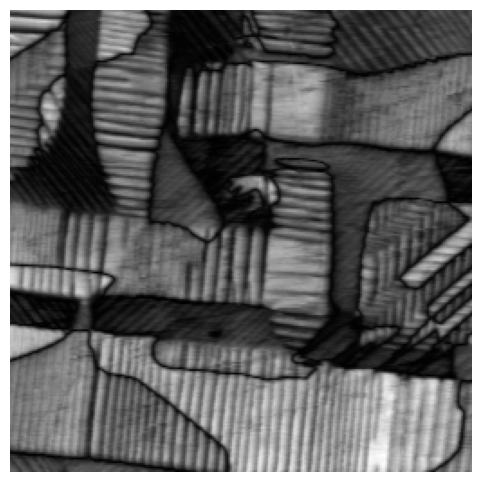

In [ ]:
channel_index = 2 #--> we want amplitude

img = img_data[channel_index].T
img = (img - img.min()) / (img.max() - img.min())

plt.figure(figsize=(6, 6))

plt.imshow(
    img,
    cmap="gray"
)

plt.axis("off")
plt.show()

Each trace contains multiple decision steps.

For every step:

- `patches` contains all candidate image patches available to the agent.
- `selected_candidate` gives the candidate selected by the agent.
- `selected_patch` contains the selected image patch.
- `position` gives the selected location in the original AFM image.
- `score` may be available for some traces.

In [ ]:
TRACE_ID = 4
STEP = 1

trace = traces[TRACE_ID]

step_data = trace[STEP - 1]

print("Selected candidate:",
      step_data["selected_candidate"])

print("Position:",
      step_data["position"])

print("Number of candidates:",
      len(step_data["patches"]))

if "score" in step_data:
    print("Score:",
          step_data["score"])

Selected candidate: 6
Position: (189, 183)
Number of candidates: 20
Score: 1.0


VISUALIZE ONE DECISION STEP

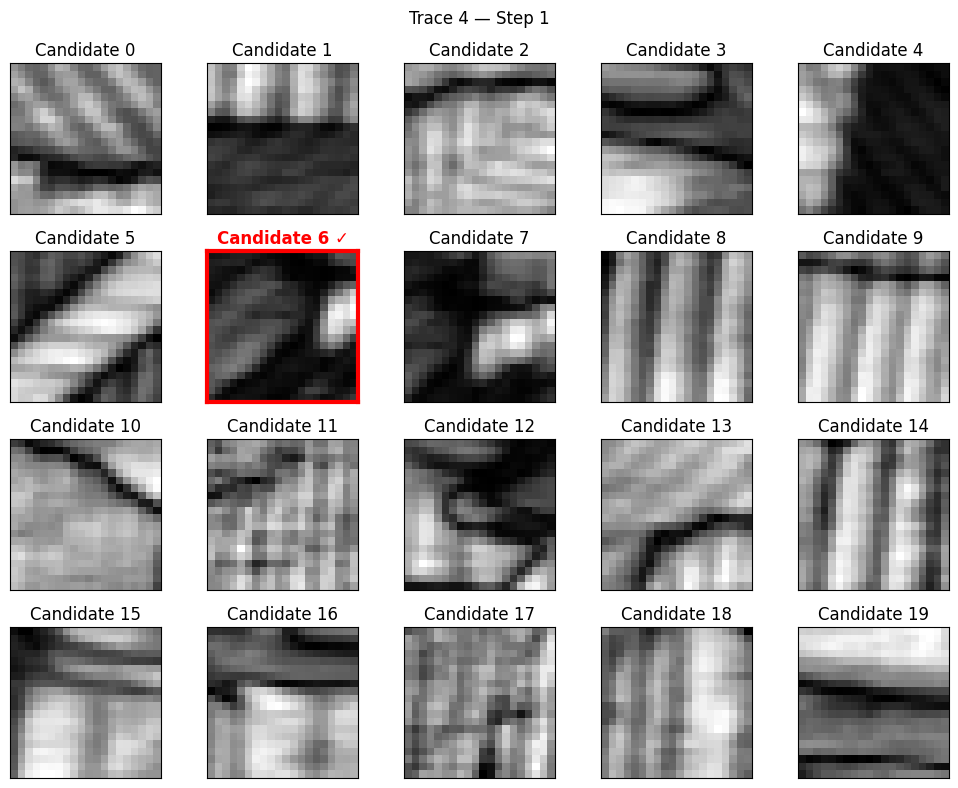

In [ ]:
patches = step_data["patches"]
selected = step_data["selected_candidate"]

n = len(patches)

ncols = 5
nrows = int(np.ceil(n / ncols))

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(10, 2 * nrows)
)

axes = np.array(axes).reshape(-1)

for i, ax in enumerate(axes):

    if i >= n:
        ax.axis("off")
        continue

    ax.imshow(
        patches[i],
        cmap="gray"
    )

    if i == selected:

        ax.set_title(
            f"Candidate {i} ✓",
            color="red",
            weight="bold"
        )

        for spine in ax.spines.values():
            spine.set_edgecolor("red")
            spine.set_linewidth(3)

    else:

        ax.set_title(
            f"Candidate {i}"
        )

    ax.set_xticks([])
    ax.set_yticks([])

plt.suptitle(
    f"Trace {TRACE_ID} — Step {STEP}"
)

plt.tight_layout()
plt.show()

TRACE MAP ON ORIGINAL IMAGE

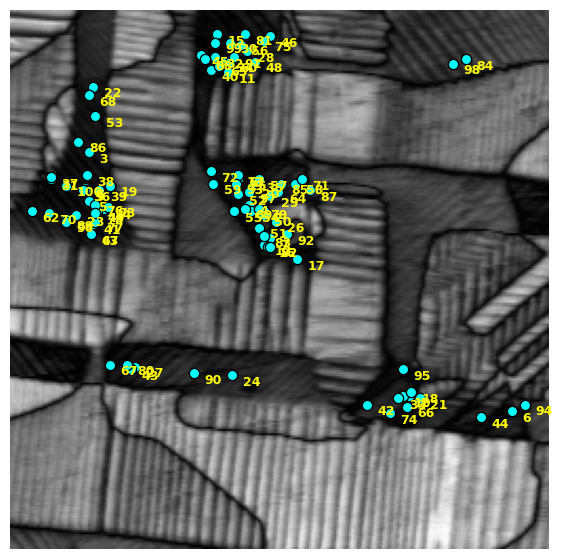

In [ ]:
trace = traces[TRACE_ID]

steps = sorted(trace.keys())

xs = [
    trace[step]["position"][0]
    for step in steps
]

ys = [
    trace[step]["position"][1]
    for step in steps
]


fig, ax = plt.subplots(
    figsize=(7, 7)
)

ax.imshow(
    img,
    cmap="gray"
)


# ------------------------------------------------------------
# Plot all selected locations
# ------------------------------------------------------------

ax.scatter(
    xs,
    ys,
    s=55,
    color="cyan",
    edgecolors="black"
)


# ------------------------------------------------------------
# Label each point by decision step
# ------------------------------------------------------------

for step, x, y in zip(
    steps,
    xs,
    ys
):

    ax.text(
        x + 5,
        y + 5,
        str(step + 1),
        fontsize=9,
        color="yellow",
        weight="bold"
    )


ax.axis("off")

plt.show()

DECISION MAPS FOR 10 TRACES

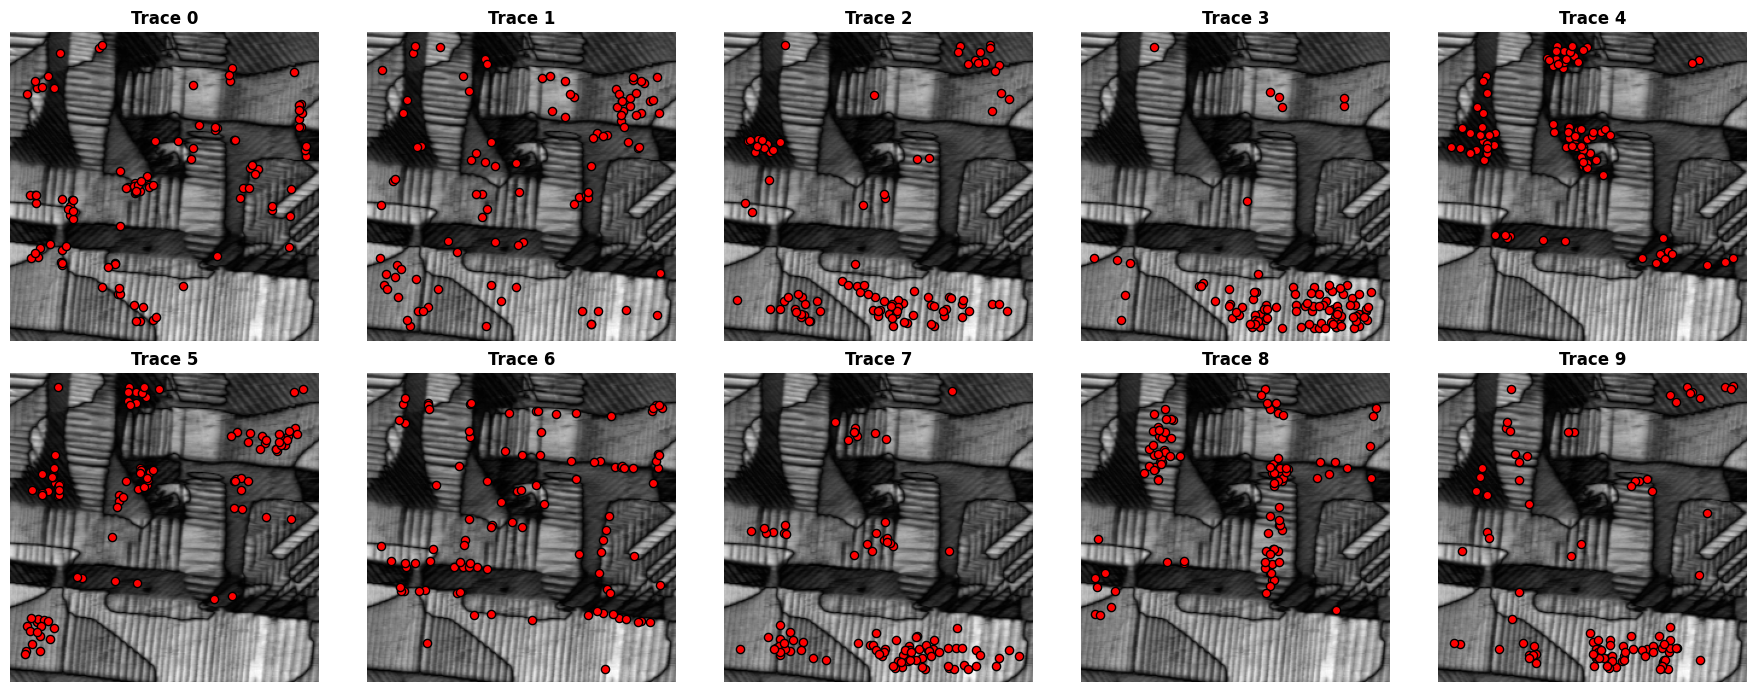

In [ ]:
TRACE_IDS = list(traces.keys())[:10]

fig, axes = plt.subplots(
    2,
    5,
    figsize=(18, 7)
)

axes = axes.flatten()


for ax, trace_id in zip(axes, TRACE_IDS):

    trace = traces[trace_id]

    steps = sorted(trace.keys())

    xs = [
        trace[step]["position"][0]
        for step in steps
    ]

    ys = [
        trace[step]["position"][1]
        for step in steps
    ]


    # Original AFM image
    ax.imshow(
        img,
        cmap="gray"
    )


    # Selected locations
    ax.scatter(
        xs,
        ys,
        s=35,
        color="r",
        edgecolors="black"
    )

    ax.set_title(
        f"Trace {trace_id}",
        fontsize=12,
        weight="bold"
    )

    ax.axis("off")


plt.tight_layout()
plt.show()

# What Makes a Patch Get Selected?

Each decision step contains 20 candidate patches, but only one was selected.
The goal is to discover visual or quantitative characteristics that may explain the hidden objective.

### DEFINE YOUR HYPOTHESIZED REWARD

### Our approach: infer a rule for each trace

At each decision, the agent chooses **one of 20 candidate patches**. We measure features of every patch (brightness, contrast, local variation, gradients, boundary-like transitions and stripe alignment), then ask which feature or combination most often scores the recorded choice highest.

We evaluate **one trace at a time**: individual high/low features, two-feature weighted rules, learned linear scores and tree-based scores. For model selection, we use **three-fold cross-validation within the first 70 decisions**. We refit the selected rule on those 70 decisions and compare its predictions with the **last 30 decisions**.

A successful reconstruction indicates that measured image characteristics predict the recorded selections. **It does not establish GPT's private reasoning, a unique hidden scoring equation, or a physical domain-wall mechanism.** The later decisions were inspected during earlier hackathon exploration, so these accuracies are *diagnostic*, not completely untouched independent tests.

**Feature extraction — image measurements only.** No hidden selection or score is used when calculating features.

In [ ]:
FEATURE_TEXT = {
    'brightness': 'average brightness', 'contrast':'brightness variation (contrast)',
    'local_variation_7':'local brightness variation', 'global_x_local':'combined global and local variation',
    'coarse_variation':'large-scale brightness variation', 'fine_texture':'small-scale texture',
    'edge_strength':'strength of image boundaries', 'edge_density':'fraction with sharp intensity changes',
    'x_gradient':'left-to-right intensity changes', 'y_gradient':'top-to-bottom intensity changes',
    'stripe_alignment':'alignment of image boundaries', 'orientation':'balance of horizontal and vertical changes',
    'boundary_x':'left-to-right light/dark transitions', 'boundary_y':'top-to-bottom light/dark transitions',
    'dominant_frequency':'strength of a repeated spatial pattern',
    'low_frequency':'large-scale image texture', 'high_frequency':'fine spatial texture',
    'gray_contrast_x':'neighbor contrast along image rows',
    'gray_contrast_y':'neighbor contrast along image columns',
    'gray_homogeneity_x':'neighbor similarity along image rows',
    'gray_homogeneity_y':'neighbor similarity along image columns',
    'largest_light_region':'fraction occupied by largest bright region',
    'largest_dark_region':'fraction occupied by largest dark region',
    'row_band':'variation across image rows', 'column_band':'variation across image columns',
    'entropy':'diversity of pixel intensities', 'skew':'asymmetry of brightness values',
    'peak_gradient':'strongest intensity boundaries',
    'edge_orientation_0':'raw gradient direction preference',
    'edge_orientation_2':'smoothed gradient direction preference',
    'stripe_alignment_0':'raw alignment', 'stripe_alignment_2':'smoothed alignment',
    'neighbor_change_x':'average difference between neighboring columns',
    'neighbor_change_y':'average difference between neighboring rows',
    'gray_energy_direction_spread':'difference in texture repetition by direction',
    'gray_homogeneity_direction_spread':'directional difference in neighbor similarity',
}

def patch_features(patch):
    a=np.asarray(patch,dtype=np.float64).squeeze()
    if a.ndim!=2: raise ValueError(f'Expected grayscale 2D patch, got {a.shape}')
    finite=a[np.isfinite(a)]
    if finite.size==0: a=np.zeros_like(a)
    else: a=np.nan_to_num(a,nan=float(np.median(finite)),posinf=float(finite.max()),neginf=float(finite.min()))
    mu=float(a.mean()); sd=float(a.std()); h,w=a.shape
    smooth1=gaussian_filter(a,1); smooth2=gaussian_filter(a,2); coarse=gaussian_filter(a,3)
    gx=sobel(smooth1,axis=1)/8; gy=sobel(smooth1,axis=0)/8
    g=np.hypot(gx,gy)
    gx0=sobel(a,axis=1)/8; gy0=sobel(a,axis=0)/8
    gx2=sobel(smooth2,axis=1)/8; gy2=sobel(smooth2,axis=0)/8
    local_mean=uniform_filter(a,size=7)
    local_var=np.maximum(0,uniform_filter(a*a,size=7)-local_mean*local_mean)
    local_std=np.sqrt(local_var)
    z=(a-mu)/(sd+1e-10)
    lim=(a-a.min())/(np.ptp(a)+1e-12)
    hist=np.histogram(lim,bins=16,range=(0,1))[0]
    probs=hist[hist>0]/max(1,hist.sum())
    power=np.abs(np.fft.fftshift(np.fft.fft2(a-mu)))**2
    power[h//2,w//2]=0
    yy,xx=np.ogrid[:h,:w]
    rad=np.hypot(yy-h//2,xx-w//2)
    total=power.sum()+1e-12
    mask=a>mu
    lab,n=label(mask)
    sizes=np.bincount(lab.ravel())[1:]
    lab2,n2=label(~mask)
    sizes2=np.bincount(lab2.ravel())[1:]
    def align(u,v):
        xx=np.mean(u*u); yy=np.mean(v*v); xy=np.mean(u*v)
        return float(np.hypot(xx-yy,2*xy)/(xx+yy+1e-12))
    def orient(u,v):
        au=np.abs(u).mean(); av=np.abs(v).mean()
        return float((au-av)/(au+av+1e-12))
    # 8 gray levels and adjacent pixel pairs: compact directional texture measurements.
    levels=np.minimum((lim*8).astype(np.int32),7)
    horizontal=levels[:,:-1]; hr=levels[:,1:]
    vertical=levels[:-1,:]; vr=levels[1:,:]
    def gray_stats(left,right):
        P=np.bincount((left*8+right).ravel(),minlength=64).reshape(8,8).astype(float)
        P/=P.sum()+1e-12
        I,J=np.indices((8,8)); diff=(I-J)**2
        return (float(np.sum(P*diff)),float(np.sum(P/(1+diff))),float(np.sum(P*P)))
    cx,hx,ex=gray_stats(horizontal,hr)
    cy,hy,ey=gray_stats(vertical,vr)
    return {
        'brightness':mu,'contrast':sd,
        'local_variation_7':float(local_std.mean()),
        'global_x_local':float(sd*local_std.mean()),
        'coarse_variation':float(coarse.std()),
        'fine_texture':float((a-smooth1).std()),
        'edge_strength':float(g.mean()),'edge_density':float(np.mean(g>max(0.35*sd,1e-10))),
        'x_gradient':float(np.abs(gx).mean()),'y_gradient':float(np.abs(gy).mean()),
        'stripe_alignment':align(gx,gy),'orientation':orient(gx,gy),
        'boundary_x':float(np.mean(mask[:,1:]!=mask[:,:-1])),
        'boundary_y':float(np.mean(mask[1:,:]!=mask[:-1,:])),
        'dominant_frequency':float(power.max()/total),
        'low_frequency':float(power[rad<2.5].sum()/total),
        'high_frequency':float(power[rad>=6].sum()/total),
        'gray_contrast_x':cx,'gray_contrast_y':cy,
        'gray_homogeneity_x':hx,'gray_homogeneity_y':hy,
        'largest_light_region':float(max(sizes,default=0)/a.size),
        'largest_dark_region':float(max(sizes2,default=0)/a.size),
        'row_band':float(coarse.mean(axis=1).std()),
        'column_band':float(coarse.mean(axis=0).std()),
        'entropy':float(-np.sum(probs*np.log2(probs))),
        'skew':float(np.mean(z**3)),
        'peak_gradient':float(np.percentile(g,95)),
        'edge_orientation_0':orient(gx0,gy0),'edge_orientation_2':orient(gx2,gy2),
        'stripe_alignment_0':align(gx0,gy0),'stripe_alignment_2':align(gx2,gy2),
        'neighbor_change_x':float(np.abs(np.diff(a,axis=1)).mean()),
        'neighbor_change_y':float(np.abs(np.diff(a,axis=0)).mean()),
        'gray_energy_direction_spread':abs(ex-ey),
        'gray_homogeneity_direction_spread':abs(hx-hy),
    }

In [ ]:
FEATURE_CACHE={}
X_BY_TRACE={}; CHOICES={}; STEP_IDS={}
for tid, trace in traces.items():
    rows=[]; chosen=[]; keys=sorted(trace)
    for step in keys:
        entry=trace[step]; step_features=[]
        for patch in entry['patches']:
            arr=np.asarray(patch)
            key=(arr.shape,arr.tobytes())
            if key not in FEATURE_CACHE: FEATURE_CACHE[key]=patch_features(arr)
            step_features.append(FEATURE_CACHE[key])
        rows.append(step_features)
        chosen.append(int(entry['selected_candidate']))
    if tid==0: FEATURE_NAMES=list(rows[0][0])
    X_BY_TRACE[tid]=np.asarray([[[r[name] for name in FEATURE_NAMES] for r in step] for step in rows],dtype=np.float32)
    CHOICES[tid]=np.asarray(chosen,dtype=int)
    STEP_IDS[tid]=keys
print(f'{len(FEATURE_NAMES)} image measurements from {len(FEATURE_CACHE)} distinct patches.')

36 image measurements from 3865 distinct patches.


**Candidate scoring rules and model comparison.** The following code searches high/low feature rules, two-feature weighted rules, linear combinations, and tree-based models.

In [ ]:
# Select a manageable, physically interpretable set for the grid search.
SIMPLE_FEATURES = [
    'brightness','contrast','local_variation_7','global_x_local','coarse_variation',
    'fine_texture','edge_strength','x_gradient','y_gradient','stripe_alignment',
    'orientation','boundary_x','boundary_y','largest_light_region','largest_dark_region',
    'row_band','column_band','low_frequency','dominant_frequency','edge_orientation_0',
    'gray_contrast_x','gray_contrast_y','neighbor_change_x','neighbor_change_y'
]
SIMPLE_IDX=np.asarray([FEATURE_NAMES.index(v) for v in SIMPLE_FEATURES])
CORES = [v for v in SIMPLE_FEATURES if v not in ('largest_light_region','largest_dark_region','dominant_frequency')]
CORE_IDX=np.asarray([FEATURE_NAMES.index(v) for v in CORES])

# Each column of W is a possible scoring equation over standardized features.
Ws=[]; families=[]
for i in range(len(SIMPLE_FEATURES)):
    for sign in (-1,1):
        w=np.zeros(len(SIMPLE_FEATURES),dtype=np.float32);w[i]=sign
        Ws.append(w);families.append('One feature')
for i,j in combinations(range(len(SIMPLE_FEATURES)),2):
    for si,sj in product((-1,1),repeat=2):
        for a in (0.25,0.50,0.75):
            w=np.zeros(len(SIMPLE_FEATURES),dtype=np.float32)
            w[i]=si*a; w[j]=sj*(1-a)
            Ws.append(w);families.append('Two features')
W=np.asarray(Ws,dtype=np.float32).T
FAMILY=np.array(families)

MODEL_SETTINGS=[{'kind':'One feature'},{'kind':'Two features'},
                {'kind':'Linear','subset':'core','penalty':0.10},
                {'kind':'Linear','subset':'all','penalty':0.30},
                {'kind':'ExtraTrees','subset':'core'},
                {'kind':'ExtraTrees','subset':'all'},
                {'kind':'RandomForest','subset':'core'}]
PRIORITY={'One feature':0,'Two features':1,'Linear':2,'ExtraTrees':3,'RandomForest':4}
print(f'{W.shape[1]:,} proposed simple scoring equations; {len(MODEL_SETTINGS)} model configurations.')

def normalize(X,train_ids):
    scaler=StandardScaler().fit(X[train_ids].reshape(-1,X.shape[-1]))
    z=scaler.transform(X.reshape(-1,X.shape[-1])).reshape(X.shape)
    return np.clip(np.nan_to_num(z,nan=0,posinf=0,neginf=0),-10,10).astype(np.float32),scaler

def fit_linear(x,y,penalty):
    def obj(beta):
        logits=x@beta
        p=softmax(logits,axis=1)
        loss=(logsumexp(logits,axis=1)-logits[np.arange(len(y)),y]).mean()+0.5*penalty*(beta@beta)
        grad=(np.einsum('tc,tcf->f',p,x)-x[np.arange(len(y)),y].sum(axis=0))/len(y)+penalty*beta
        return float(loss),grad
    opt=minimize(obj,np.zeros(x.shape[-1]),jac=True,method='L-BFGS-B',options={'maxiter':180})
    return opt.x

def fit_trees(name,x,y):
    z=np.zeros((len(y),x.shape[1]),dtype=int)
    z[np.arange(len(y)),y]=1
    if name=='ExtraTrees':
        model=ExtraTreesClassifier(n_estimators=N_TREES,min_samples_leaf=2,
                                   max_features=0.75,class_weight='balanced',random_state=SEED,n_jobs=-1)
    else:
        model=RandomForestClassifier(n_estimators=N_TREES,min_samples_leaf=3,
                                     max_features=0.75,class_weight='balanced',random_state=SEED,n_jobs=-1)
    model.fit(x.reshape(-1,x.shape[-1]),z.ravel())
    return model

def tree_scores(model,x):
    proba=model.predict_proba(x.reshape(-1,x.shape[-1]))
    idx=list(model.classes_).index(1)
    return proba[:,idx].reshape(x.shape[:2])

def family_best_rule(scores,y,train_ids,family):
    allowed=np.flatnonzero(FAMILY==family)
    preds=np.argmax(scores[train_ids][:,:,allowed],axis=1)
    wins=(preds==y[train_ids,None]).sum(axis=0)
    return int(allowed[np.argmax(wins)])

def fit_setting(setting,z,y,ids):
    kind=setting['kind']
    if kind in ('One feature','Two features'):
        all_scores=np.matmul(z[:,:,SIMPLE_IDX],W)
        which=family_best_rule(all_scores,y,ids,kind)
        weights=np.zeros(z.shape[-1]);weights[SIMPLE_IDX]=W[:,which]
        return {'kind':kind,'weights':weights,'model':None,'idx':np.arange(z.shape[-1])}
    idx=CORE_IDX if setting.get('subset')=='core' else np.arange(z.shape[-1])
    if kind=='Linear':
        w=fit_linear(z[ids][:,:,idx],y[ids],setting['penalty'])
        weights=np.zeros(z.shape[-1]);weights[idx]=w
        return {'kind':kind,'weights':weights,'model':None,'idx':idx}
    model=fit_trees(kind,z[ids][:,:,idx],y[ids])
    return {'kind':kind,'weights':None,'model':model,'idx':idx}

def score_model(fitted,z):
    if fitted['weights'] is not None:return np.matmul(z,fitted['weights'])
    return tree_scores(fitted['model'],z[:,:,fitted['idx']])

3,360 proposed simple scoring equations; 7 model configurations.


In [ ]:
# Fit, select and evaluate one independent scoring function for each trace.
TRACE_MODELS={}; report=[]; predictions=[]; CV_DETAILS=[]
started=time.time()
for tid in sorted(traces):
    raw=X_BY_TRACE[tid].astype(np.float64)
    y=CHOICES[tid]; n=len(y)
    cutoff=max(20,min(n-10,int(round(n*TRAIN_FRACTION))))
    splits=KFold(n_splits=CV_FOLDS,shuffle=False).split(np.arange(cutoff))
    cv_hits=np.zeros(len(MODEL_SETTINGS),dtype=int)
    for train_ids,val_ids in splits:
        z,_=normalize(raw,train_ids)
        for j,setting in enumerate(MODEL_SETTINGS):
            fitted=fit_setting(setting,z,y,train_ids)
            sc=score_model(fitted,z[val_ids])
            cv_hits[j]+=int((sc.argmax(axis=1)==y[val_ids]).sum())
    # A margin of two correct choices out of 70 avoids adding complexity for tiny gains.
    eligible=np.flatnonzero(cv_hits>=cv_hits.max()-2)
    best_id=min(eligible,key=lambda j:(PRIORITY[MODEL_SETTINGS[j]['kind']],-cv_hits[j]))
    setting=MODEL_SETTINGS[int(best_id)]
    z,scaler=normalize(raw,np.arange(cutoff))
    fitted=fit_setting(setting,z,y,np.arange(cutoff))
    scores=score_model(fitted,z)
    guess=scores.argmax(axis=1)
    top3=np.argsort(-scores,axis=1)[:,:3]
    correct=(guess==y)
    top3_ok=(top3==y[:,None]).any(axis=1)
    test_correct=int(correct[cutoff:].sum()); test_total=n-cutoff
    cv_accuracy=int(cv_hits[best_id])/cutoff
    test_accuracy=test_correct/test_total
    if test_accuracy>=0.90: status='Strong reconstruction'
    elif test_accuracy>=0.80: status='Good reconstruction'
    elif test_accuracy>=0.70: status='Promising / partial'
    else: status='Unresolved rule'
    fitted.update({'scaler':scaler,'scores':scores,'cutoff':cutoff,'predicted':guess,'correct':correct,
                   'top3':top3_ok,'cv_accuracy':cv_accuracy,'test_accuracy':test_accuracy,'status':status})
    TRACE_MODELS[tid]=fitted
    report.append({'Trace':tid,'Source':SOURCE_LABEL[tid],'Rule':setting['kind'],
                   'CV top-1':cv_accuracy,'Train top-1':correct[:cutoff].mean(),
                   'Later top-1':test_accuracy,'Later top-3':top3_ok[cutoff:].mean(),
                   'Reconstructed':f'{int(correct.sum())}/{n}','Status':status})
    for i,k in enumerate(STEP_IDS[tid]):
        predictions.append({'trace':tid,'decision':i+1,'original_step':k,'split':'train' if i<cutoff else 'later',
                            'actual':int(y[i]),'predicted':int(guess[i]),'correct':bool(correct[i])})
    for s,hit in zip(MODEL_SETTINGS,cv_hits):
        CV_DETAILS.append({'trace':tid,'model':s['kind'],'settings':str(s),'correct':int(hit),'out_of':cutoff})
    print(f'{SOURCE_LABEL[tid]:6} | {setting["kind"]:12} | CV {cv_accuracy:5.1%} | '
          f'later {test_correct:2}/{test_total} ({test_accuracy:5.1%}) | {status}',flush=True)

SUMMARY=pd.DataFrame(report)
PREDICTIONS=pd.DataFrame(predictions)
CV_RESULTS=pd.DataFrame(CV_DETAILS)
SUMMARY.to_csv(OUTPUT_DIR/'trace_summary.csv',index=False)
PREDICTIONS.to_csv(OUTPUT_DIR/'decision_predictions.csv',index=False)
CV_RESULTS.to_csv(OUTPUT_DIR/'model_comparison.csv',index=False)
print(f'\nAnalysis completed in {time.time()-started:.1f} seconds.')
display(SUMMARY.style.format({'CV top-1':'{:.1%}','Train top-1':'{:.1%}',
                              'Later top-1':'{:.1%}','Later top-3':'{:.1%}'}))

GPT 0  | ExtraTrees   | CV 30.0% | later 13/30 (43.3%) | Unresolved rule
GPT 1  | Two features | CV 25.7% | later  6/30 (20.0%) | Unresolved rule
GPT 2  | Two features | CV 62.9% | later 10/30 (33.3%) | Unresolved rule
Sim 0  | One feature  | CV 98.6% | later 30/30 (100.0%) | Strong reconstruction
Sim 1  | One feature  | CV 98.6% | later 30/30 (100.0%) | Strong reconstruction
Sim 2  | One feature  | CV 95.7% | later 29/30 (96.7%) | Strong reconstruction
Sim 3  | Two features | CV 30.0% | later  7/30 (23.3%) | Unresolved rule
Sim 4  | Linear       | CV 82.9% | later 22/30 (73.3%) | Promising / partial
Sim 5  | One feature  | CV 81.4% | later 22/30 (73.3%) | Promising / partial
Sim 6  | Linear       | CV 54.3% | later 19/30 (63.3%) | Unresolved rule
Sim 7  | Linear       | CV 65.7% | later 21/30 (70.0%) | Promising / partial

Analysis completed in 41.6 seconds.


,Trace,Source,Rule,CV top-1,Train top-1,Later top-1,Later top-3,Reconstructed,Status
0,0,GPT 0,ExtraTrees,30.0%,100.0%,43.3%,63.3%,83/100,Unresolved rule
1,1,GPT 1,Two features,25.7%,32.9%,20.0%,50.0%,29/100,Unresolved rule
2,2,GPT 2,Two features,62.9%,65.7%,33.3%,66.7%,56/100,Unresolved rule
3,3,Sim 0,One feature,98.6%,98.6%,100.0%,100.0%,99/100,Strong reconstruction
4,4,Sim 1,One feature,98.6%,98.6%,100.0%,100.0%,99/100,Strong reconstruction
5,5,Sim 2,One feature,95.7%,95.7%,96.7%,100.0%,96/100,Strong reconstruction
6,6,Sim 3,Two features,30.0%,35.7%,23.3%,43.3%,32/100,Unresolved rule
7,7,Sim 4,Linear,82.9%,81.4%,73.3%,100.0%,79/100,Promising / partial
8,8,Sim 5,One feature,81.4%,81.4%,73.3%,90.0%,79/100,Promising / partial
9,9,Sim 6,Linear,54.3%,64.3%,63.3%,86.7%,64/100,Unresolved rule


**Model used by the original notebook.** We keep its `reward(patch)` interface so the organizer’s original scoring grid and benchmark cells below still work.

In [ ]:
# The original notebook calls reward(patch) for the active TRACE_ID.
# Different traces have different fitted rules.
def reward(patch):
    tid=int(TRACE_ID)
    fit=TRACE_MODELS[tid]
    arr=np.asarray(patch)
    key=(arr.shape,arr.tobytes())
    vals=FEATURE_CACHE.get(key)
    if vals is None:
        vals=patch_features(arr)
        FEATURE_CACHE[key]=vals
    raw=np.array([[vals[name] for name in FEATURE_NAMES]],dtype=np.float64)
    z=np.clip(np.nan_to_num(fit['scaler'].transform(raw),nan=0,posinf=0,neginf=0),-10,10)
    if fit['weights'] is not None:
        return float(z[0] @ fit['weights'])
    class_1=list(fit['model'].classes_).index(1)
    return float(fit['model'].predict_proba(z[:,fit['idx']])[0,class_1])
print('Original reward(patch) interface now uses the inferred rule for each TRACE_ID.')

Original reward(patch) interface now uses the inferred rule for each TRACE_ID.


### SCORE ALL PATCHES IN ONE STEP

In [ ]:
TRACE_ID = 6
STEP = 1

trace = traces[TRACE_ID]
step_data = trace[STEP - 1]

patches = step_data["patches"]
actual_selected = step_data["selected_candidate"]


# Score all 20 candidates
scores = np.array([
    reward(patch)
    for patch in patches
])


# Select highest-scoring candidate
predicted_selected = int(
    np.argmax(scores)
)

print(
    f"Actual selection:    Candidate {actual_selected}"
)

print(
    f"Predicted selection: Candidate {predicted_selected}"
)

Actual selection:    Candidate 16
Predicted selection: Candidate 5



### VISUALIZE PREDICTED vs ACTUAL CLEARLY

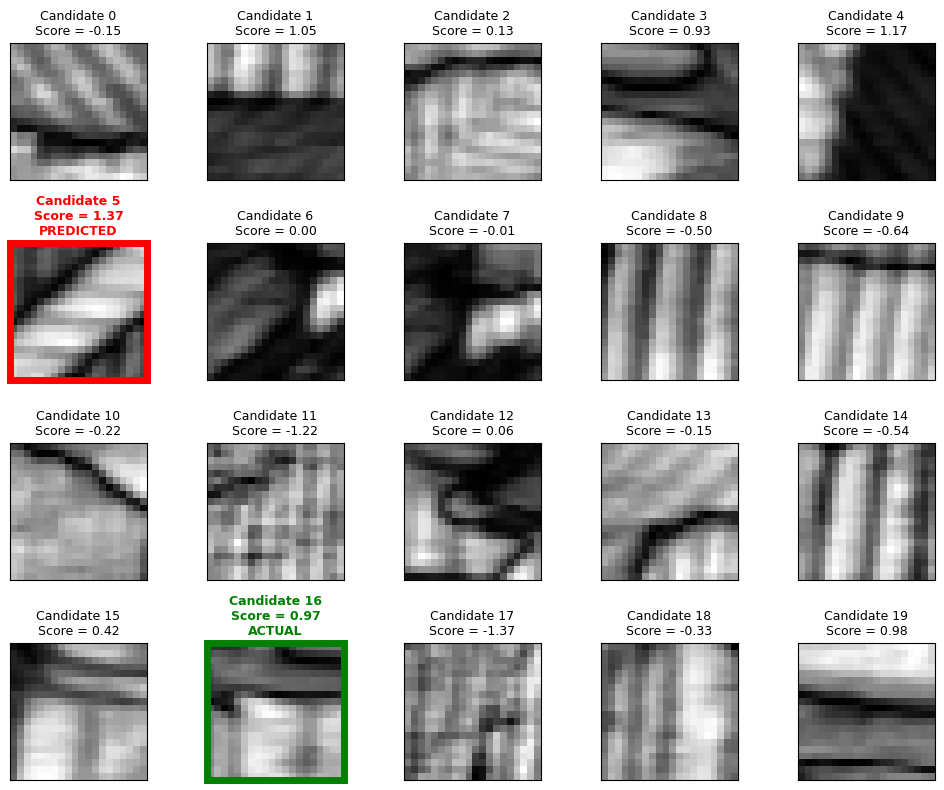

In [ ]:
fig, axes = plt.subplots(
    4,
    5,
    figsize=(10, 8)
)

for i, ax in enumerate(axes.flat):

    ax.imshow(
        patches[i],
        cmap="gray"
    )

    ax.set_title(
        f"Candidate {i}\nScore = {scores[i]:.2f}",
        fontsize=9
    )

    # --------------------------------------------------------
    # Highlight selections
    # --------------------------------------------------------

    if i == actual_selected and i == predicted_selected:

        for spine in ax.spines.values():
            spine.set_edgecolor("blue")
            spine.set_linewidth(5)

        ax.set_title(
            f"Candidate {i}\n"
            f"Score = {scores[i]:.2f}\n"
            f"ACTUAL + PREDICTED",
            fontsize=9,
            color="blue",
            weight="bold"
        )

    elif i == actual_selected:

        for spine in ax.spines.values():
            spine.set_edgecolor("green")
            spine.set_linewidth(5)

        ax.set_title(
            f"Candidate {i}\n"
            f"Score = {scores[i]:.2f}\n"
            f"ACTUAL",
            fontsize=9,
            color="green",
            weight="bold"
        )

    elif i == predicted_selected:

        for spine in ax.spines.values():
            spine.set_edgecolor("red")
            spine.set_linewidth(5)

        ax.set_title(
            f"Candidate {i}\n"
            f"Score = {scores[i]:.2f}\n"
            f"PREDICTED",
            fontsize=9,
            color="red",
            weight="bold"
        )

    ax.set_xticks([])
    ax.set_yticks([])


plt.tight_layout()
plt.show()

### BENCHMARK HYPOTHESIZED REWARD ACROSS ALL STEPS

In [ ]:
results = []

for step in sorted(trace.keys()):

    step_data = trace[step]

    patches = step_data["patches"]
    actual_selected = step_data["selected_candidate"]

    # Score all candidates in this step
    scores = np.array([
        reward(patch)
        for patch in patches
    ])

    # Predicted choice = highest score
    predicted_selected = int(
        np.argmax(scores)
    )

    results.append({
        "step": step + 1,
        "actual": actual_selected,
        "predicted": predicted_selected,
        "correct": int(
            predicted_selected == actual_selected
        )
    })


results = pd.DataFrame(results)

accuracy = results["correct"].mean()

print(f"Trace {TRACE_ID}")
print(f"Accuracy: {accuracy:.1%}")
print(f"Correct: {results['correct'].sum()} / {len(results)}")
print(f"Random baseline: {1 / len(trace[0]['patches']):.1%}")

results

Trace 6
Accuracy: 32.0%
Correct: 32 / 100
Random baseline: 5.0%


,step,actual,predicted,correct
0,1,16,5,0
1,2,2,11,0
2,3,12,12,1
3,4,6,8,0
4,5,8,5,0
...,...,...,...,...
95,96,5,4,0
96,97,1,11,0
97,98,3,4,0
98,99,5,16,0


**Important:** the original notebook benchmark immediately above averages **all** decisions, including ones used for fitting. For prediction on decisions not used to fit that trace's final weights, use the **Later top-1** column in the summary below.

## Results — same trace numbers as the original notebook

In [ ]:
# Keep the trace labels 0–10 consistent with the original notebook.
print('One fitted rule per trace:')
display(SUMMARY[['Trace','Source','Rule','CV top-1','Train top-1','Later top-1','Later top-3','Reconstructed','Status']]
        .style.format({'CV top-1':'{:.1%}','Train top-1':'{:.1%}','Later top-1':'{:.1%}','Later top-3':'{:.1%}'}))
print('Random top-1 baseline = 5%; random top-3 baseline = 15%.')

One fitted rule per trace:


,Trace,Source,Rule,CV top-1,Train top-1,Later top-1,Later top-3,Reconstructed,Status
0,0,GPT 0,ExtraTrees,30.0%,100.0%,43.3%,63.3%,83/100,Unresolved rule
1,1,GPT 1,Two features,25.7%,32.9%,20.0%,50.0%,29/100,Unresolved rule
2,2,GPT 2,Two features,62.9%,65.7%,33.3%,66.7%,56/100,Unresolved rule
3,3,Sim 0,One feature,98.6%,98.6%,100.0%,100.0%,99/100,Strong reconstruction
4,4,Sim 1,One feature,98.6%,98.6%,100.0%,100.0%,99/100,Strong reconstruction
5,5,Sim 2,One feature,95.7%,95.7%,96.7%,100.0%,96/100,Strong reconstruction
6,6,Sim 3,Two features,30.0%,35.7%,23.3%,43.3%,32/100,Unresolved rule
7,7,Sim 4,Linear,82.9%,81.4%,73.3%,100.0%,79/100,Promising / partial
8,8,Sim 5,One feature,81.4%,81.4%,73.3%,90.0%,79/100,Promising / partial
9,9,Sim 6,Linear,54.3%,64.3%,63.3%,86.7%,64/100,Unresolved rule


Random top-1 baseline = 5%; random top-3 baseline = 15%.


**Reading this table.** *CV top-1* is the fraction correctly predicted in three validation folds within the first 70 choices; *Train top-1* is the fit to those 70 choices after model selection; *Later top-1* is the fraction correctly predicted for the last 30 choices; *Later top-3* checks whether the selected candidate was among the model's three highest-scoring patches. *Reconstructed* counts both training and later decisions, so it **must not** be used alone to claim predictive accuracy (e.g. GPT 0 has 83/100 overall, but 13/30 on later decisions). Random top-1 and top-3 accuracy would be 5% and 15% with 20 equally likely candidates.

In [ ]:
def explain_fitted(tid):
    fit=TRACE_MODELS[tid]
    w=fit['weights']
    if w is not None:
        ids=np.flatnonzero(np.abs(w)>1e-5)
        ids=sorted(ids,key=lambda i:-abs(w[i]))
        direction=['higher' if w[i]>0 else 'lower' for i in ids[:3]]
        traits=[f'{direction[j]} {FEATURE_TEXT.get(FEATURE_NAMES[i],FEATURE_NAMES[i].replace("_"," "))}'
                for j,i in enumerate(ids[:3])]
        if fit['kind']=='One feature':
            rule=f'Select the patch with {traits[0]}.'
        elif fit['kind']=='Two features':
            rule='Rank patches using a weighted combination of '+ ' and '.join(traits[:2])+'.'
        else:
            rule='Learned weighted score emphasizing '+', '.join(traits)+'.'
        terms=[f'{w[i]:+.2f}×z({FEATURE_NAMES[i]})' for i in ids[:5]]
        equation='Score = '+' '.join(terms)
        if len(ids)>5: equation+=f' + {len(ids)-5} other terms'
    else:
        importances=fit['model'].feature_importances_
        cols=fit['idx']
        ids=cols[np.argsort(-importances)[:3]]
        traits=[FEATURE_TEXT.get(FEATURE_NAMES[i],FEATURE_NAMES[i].replace('_',' ')) for i in ids]
        rule=f"A nonlinear model mainly uses {', '.join(traits)}; no single short weighted equation describes it."
        equation=f"{fit['kind']} scoring model (nonlinear)"
    return rule,equation

for tid in sorted(traces):
    fit=TRACE_MODELS[tid]
    rule,equation=explain_fitted(tid)
    print(f'\n{SOURCE_LABEL[tid]}  |  {fit["status"]}  |  CV {fit["cv_accuracy"]:.0%}, later {fit["test_accuracy"]:.1%}')
    print('  Observed rule:',rule)
    print('  Model:',equation)
    if fit['test_accuracy']<0.70:
        print('  Interpretation: incomplete; do not claim the hidden decision rule was recovered.')
    elif fit['test_accuracy']<0.90:
        print('  Interpretation: a substantial fraction of choices is explained, but some behavior remains unexplained.')
    else:
        print('  Interpretation: most recorded choices are reproduced; exact internal logic is not confirmed.')


GPT 0  |  Unresolved rule  |  CV 30%, later 43.3%
  Observed rule: A nonlinear model mainly uses strongest intensity boundaries, small-scale texture, average difference between neighboring rows; no single short weighted equation describes it.
  Model: ExtraTrees scoring model (nonlinear)
  Interpretation: incomplete; do not claim the hidden decision rule was recovered.

GPT 1  |  Unresolved rule  |  CV 26%, later 20.0%
  Observed rule: Rank patches using a weighted combination of lower local brightness variation and higher fraction occupied by largest bright region.
  Model: Score = -0.50×z(local_variation_7) +0.50×z(largest_light_region)
  Interpretation: incomplete; do not claim the hidden decision rule was recovered.

GPT 2  |  Unresolved rule  |  CV 63%, later 33.3%
  Observed rule: Rank patches using a weighted combination of higher left-to-right light/dark transitions and lower large-scale image texture.
  Model: Score = +0.75×z(boundary_x) -0.25×z(low_frequency)
  Interpretatio

## Original-style reconstruction figures
The following plots restore the analyses we developed earlier: original **blue circles versus reconstructed orange crosses**, a panel for each trace, and the **TRAIN/TEST feature-preference heatmaps**. These are deliberately kept separate from publication-oriented comparison figures.

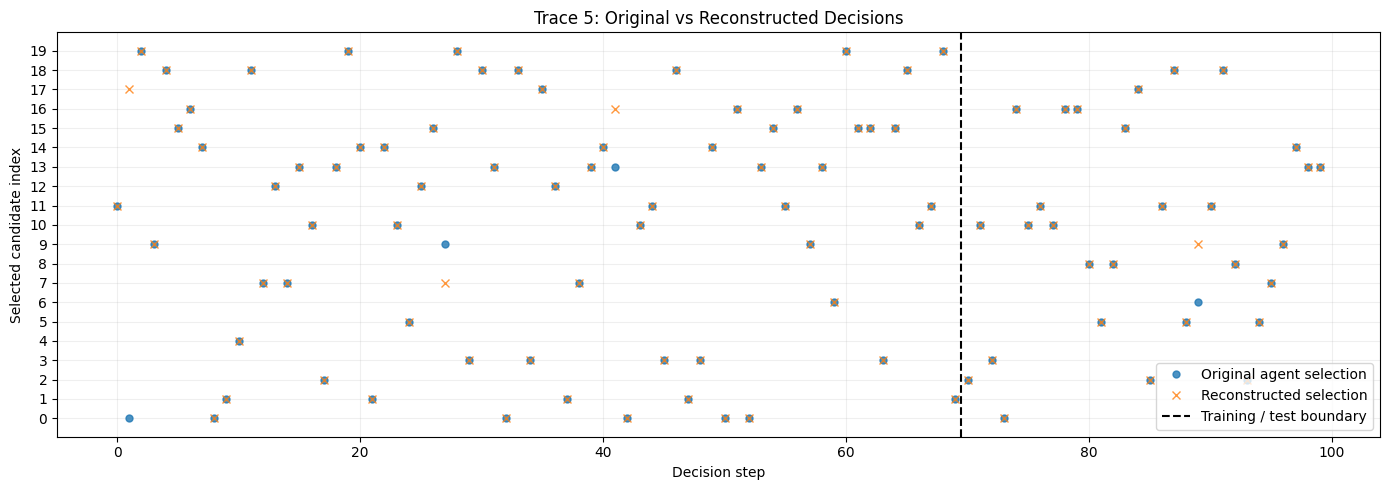

In [ ]:
# ORIGINAL vs RECONSTRUCTED — the earlier overlapping circle/X plot.
TRACE_TO_PLOT=5  # change this to inspect a different trace
fit=TRACE_MODELS[TRACE_TO_PLOT]
actual=CHOICES[TRACE_TO_PLOT]
pred=fit['predicted']
fig,ax=plt.subplots(figsize=(14,5))
ax.plot(np.arange(len(actual)),actual,'o',label='Original agent selection',markersize=5,alpha=0.8)
ax.plot(np.arange(len(pred)),pred,'x',label='Reconstructed selection',markersize=6,alpha=0.8)
ax.axvline(fit['cutoff']-0.5,ls='--',color='black',label='Training / test boundary')
ax.set_xlabel('Decision step');ax.set_ylabel('Selected candidate index')
ax.set_title(f'Trace {TRACE_TO_PLOT}: Original vs Reconstructed Decisions')
ax.set_yticks(range(20));ax.legend();ax.grid(alpha=0.2)
plt.tight_layout();save_figure(fig,f'original_style_trace_{TRACE_TO_PLOT}_reconstruction');plt.show()

*Figure — Example reconstruction (Trace 5 / Simulated 2).* Blue circles denote the agent's original selected candidate at each step, orange crosses indicate our predicted candidate, and the dashed line separates the 70 training decisions from the 30 later decisions. Overlapping markers represent a correct match. Candidate numbers are identifiers, not physical image coordinates.

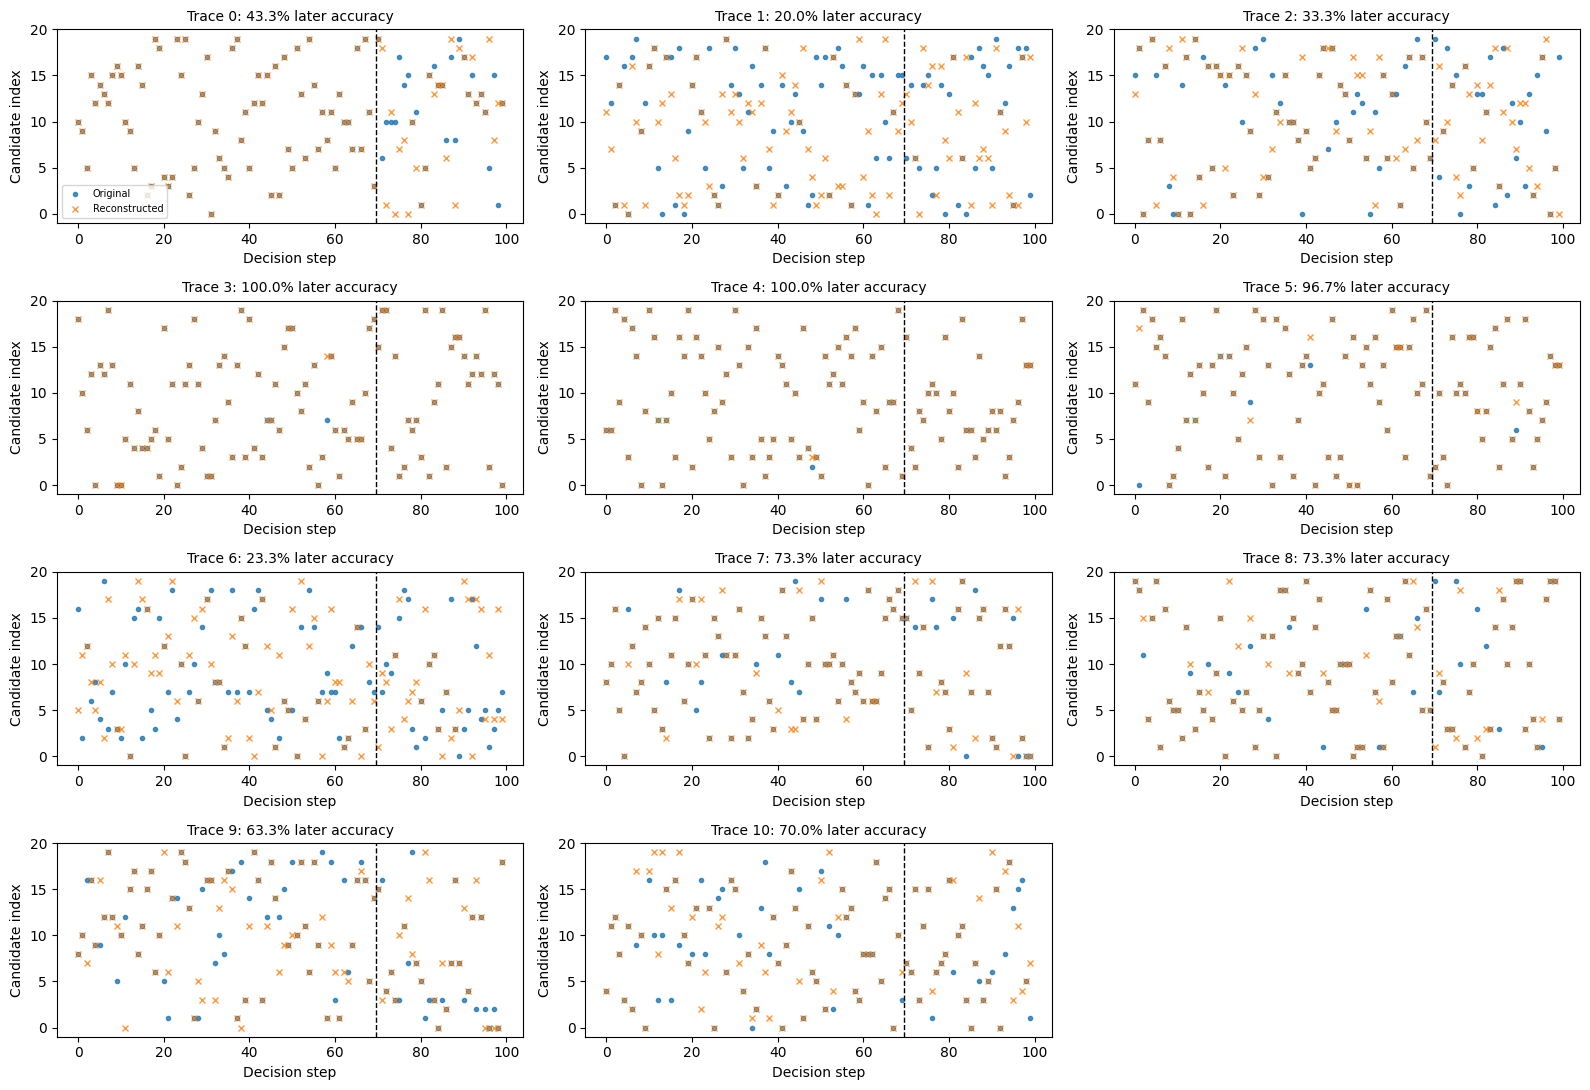

In [ ]:
# MATCHING RECONSTRUCTION FIGURE FOR ALL 11 TRACES (blue circles/orange crosses).
fig,axes=plt.subplots(4,3,figsize=(16,11))
for ax,tid in zip(axes.ravel(),sorted(traces)):
    fit=TRACE_MODELS[tid];n=len(CHOICES[tid]);steps=np.arange(n)
    ax.plot(steps,CHOICES[tid],'o',markersize=3,alpha=.8,label='Original')
    ax.plot(steps,fit['predicted'],'x',markersize=4,alpha=.8,label='Reconstructed')
    ax.axvline(fit['cutoff']-.5,ls='--',color='black',lw=1)
    ax.set_title(f'Trace {tid}: {fit["test_accuracy"]:.1%} later accuracy',fontsize=10)
    ax.set_xlabel('Decision step');ax.set_ylabel('Candidate index');ax.set_ylim(-1,20)
for ax in axes.ravel()[len(traces):]:ax.axis('off')
axes.ravel()[0].legend(fontsize=7)
plt.tight_layout();save_figure(fig,'original_style_all_11_reconstruction');plt.show()

*Figure — Reconstruction across all traces.* Each small panel uses the original blue-circle/orange-cross format. The percentage in each panel's title refers to the **later 30 decisions**, not the fit to all 100. Clear agreement on the simulated brightness and uniformity traces contrasts with more variable GPT decisions.

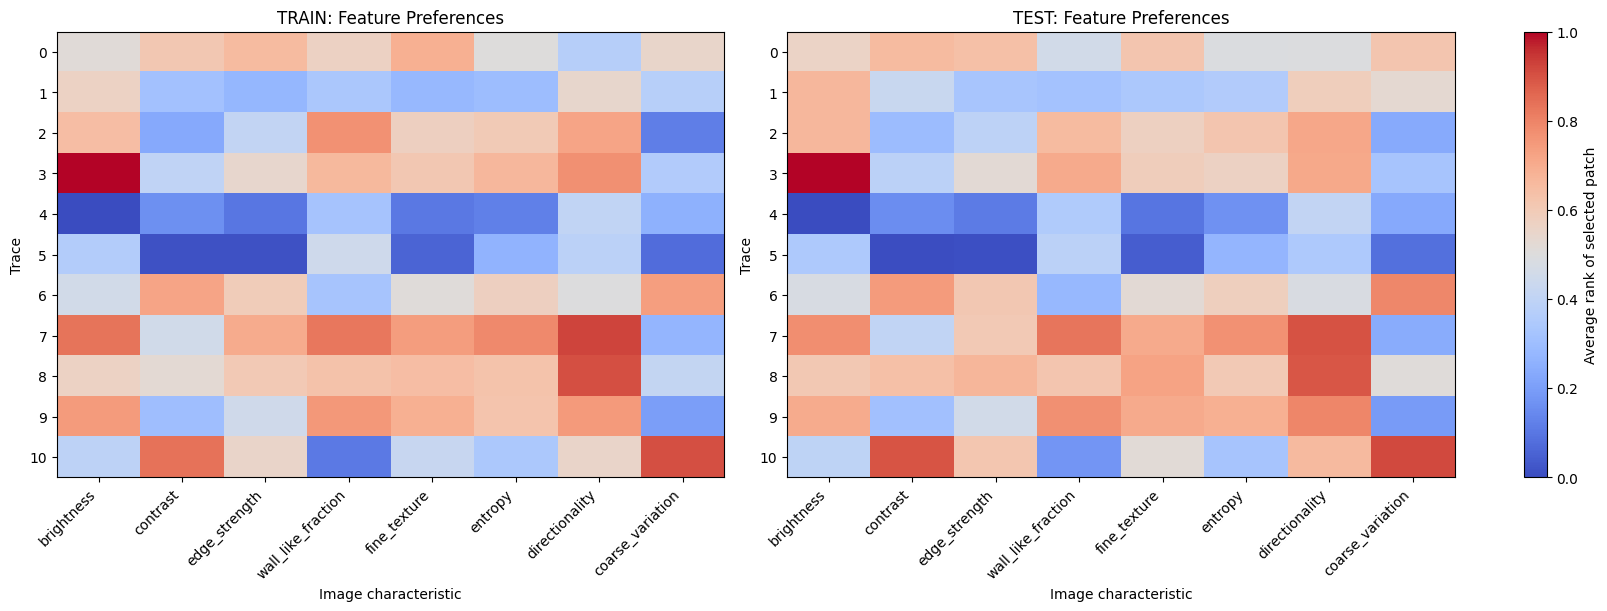

Trace 5: average selected-patch feature ranks (0 = low, 1 = high)


split,TEST,TRAIN
brightness,0.347,0.362
contrast,0.007,0.013
edge_strength,0.009,0.014
wall_like_fraction,0.385,0.448
fine_texture,0.040,0.056
entropy,0.272,0.263
directionality,0.346,0.386
coarse_variation,0.082,0.077


In [ ]:
# EXACT TWO-PANEL TRAIN / TEST FEATURE-PREFERENCE HEATMAP LAYOUT.
FEATURE_MAP={
 'brightness':'brightness',
 'contrast':'contrast',
 'edge_strength':'edge_strength',
 'wall_like_fraction':'edge_density',
 'fine_texture':'fine_texture',
 'entropy':'entropy',
 'directionality':'stripe_alignment',
 'coarse_variation':'coarse_variation'
}
PREFERENCE_ROWS=[]
for tid in sorted(traces):
    X=X_BY_TRACE[tid];y=CHOICES[tid];ntrain=TRACE_MODELS[tid]['cutoff']
    for i in range(len(y)):
        row={'trace':tid,'split':'TRAIN' if i<ntrain else 'TEST'}
        for nice,feature in FEATURE_MAP.items():
            values=X[i,:,FEATURE_NAMES.index(feature)]
            rank=(rankdata(values,method='average')-1)/(len(values)-1)
            row[nice]=rank[y[i]]
        PREFERENCE_ROWS.append(row)
FEATURE_RANKS=pd.DataFrame(PREFERENCE_ROWS)
FEATURE_LABELS=list(FEATURE_MAP)
fig,axes=plt.subplots(1,2,figsize=(16,6),constrained_layout=True)
for ax,split in zip(axes,['TRAIN','TEST']):
    mat=FEATURE_RANKS[FEATURE_RANKS['split']==split].groupby('trace')[FEATURE_LABELS].mean().reindex(sorted(traces))
    im=ax.imshow(mat.to_numpy(),cmap='coolwarm',vmin=0,vmax=1,aspect='auto')
    ax.set_xticks(range(len(FEATURE_LABELS)))
    ax.set_xticklabels(FEATURE_LABELS,rotation=45,ha='right')
    ax.set_yticks(range(len(mat)))
    ax.set_yticklabels(mat.index)
    ax.set_xlabel('Image characteristic');ax.set_ylabel('Trace')
    ax.set_title(f'{split}: Feature Preferences')
fig.colorbar(im,ax=axes,label='Average rank of selected patch')
save_figure(fig,'original_style_feature_preferences_train_vs_test');plt.show()
print('Trace 5: average selected-patch feature ranks (0 = low, 1 = high)')
display(FEATURE_RANKS[FEATURE_RANKS['trace']==5].groupby('split')[FEATURE_LABELS].mean().T.round(3))

*Figure — Image-feature preferences.* The two heatmaps give the mean percentile rank of the selected patch among the 20 candidates for each visual measurement. Values close to **0** indicate selections near the **lowest** feature values, while values near **1** indicate the highest. Train and later decisions are plotted separately. A feature preference is a correlation with choice, **not proof of a causal selection rule**.

### Additional GPT check — consistent visual preferences versus exact reconstruction

The GPT traces are difficult to reconstruct exactly, but we can still test whether the selected patches differ from the other 19 options more often than expected by random choice. The simple permutation test below randomly reselects one candidate at each step, preserving the 20 available images, and compares the strongest observed feature preference with the random baseline. This is **descriptive exploratory evidence**, not proof of GPT’s hidden reasoning.

In [ ]:
# GPT-only diagnostic: do selected image characteristics consistently differ from chance?
# Use the same eight image measurements as the restored TRAIN/TEST heatmaps.
B=1000  # number of simulated random-selection sequences
rng=np.random.default_rng(2026)
GPT_PREF_ROWS=[]
feature_idxs=[FEATURE_NAMES.index(v) for v in FEATURE_MAP.values()]
for tid in (0,1,2):
    X=X_BY_TRACE[tid][:,:,feature_idxs]
    yy=CHOICES[tid]
    nsteps,noptions,nfeatures=X.shape
    ranks=np.stack([rankdata(X[:,:,j],axis=1,method='average')
                    for j in range(nfeatures)],axis=-1)
    ranks=(ranks-1)/(noptions-1)
    chosen_ranks=ranks[np.arange(nsteps),yy,:]
    observed=chosen_ranks.mean(axis=0)
    random_indices=rng.integers(noptions,size=(B,nsteps))
    null_ranks=ranks[np.arange(nsteps)[None,:],random_indices,:].mean(axis=1)
    # Family-wise adjustment for trying eight different features on the same trace.
    max_null=np.max(np.abs(null_ranks-0.5),axis=1)
    for j,label_name in enumerate(FEATURE_MAP.keys()):
        deviation=abs(observed[j]-0.5)
        p_adj=(1+np.count_nonzero(max_null>=deviation))/(B+1)
        cutoff=TRACE_MODELS[tid]['cutoff']
        GPT_PREF_ROWS.append({'Trace':tid,'Feature':label_name,
          'Training rank':chosen_ranks[:cutoff,j].mean(),
          'Later rank':chosen_ranks[cutoff:,j].mean(),
          'Overall rank':observed[j],
          'Permutation p (8-feature adjusted)':p_adj})
GPT_PREFERENCES=pd.DataFrame(GPT_PREF_ROWS)
strongest=GPT_PREFERENCES.loc[GPT_PREFERENCES.groupby('Trace')['Overall rank'].apply(
    lambda a:(a-0.5).abs().idxmax()).to_numpy()].sort_values('Trace')
print('GPT image feature preferences (0 = low, 1 = high); corrected random-choice comparisons:')
display(strongest.round(3))
GPT_PREFERENCES.to_csv(OUTPUT_DIR/'gpt_visual_preferences.csv',index=False)
print('Note: consistent selection preferences do not imply that all individual choices can be reconstructed.')

GPT image feature preferences (0 = low, 1 = high); corrected random-choice comparisons:


,Trace,Feature,Training rank,Later rank,Overall rank,Permutation p (8-feature adjusted)
4,0,fine_texture,0.689,0.618,0.668,0.001
10,1,edge_strength,0.274,0.332,0.291,0.001
23,2,coarse_variation,0.117,0.237,0.153,0.001


Note: consistent selection preferences do not imply that all individual choices can be reconstructed.


**Interpreting the GPT permutation results:** The random-choice test asks whether the observed selection of unusually high/low image-feature values would be common if the selected candidate were random at each recorded step. We correct for checking eight features *within each GPT trace*. A small adjusted p-value supports a descriptive selection preference; it does **not** mean we can reconstruct each GPT decision or infer domain-wall physics.

## Additional paper-oriented figures and model checks
These are **supplements**, not replacements for the original notebook plots. SVG and high-resolution PNG versions are saved for figure editing. The simple candidate-order baseline checks whether selections can be predicted without looking at the image.

In [ ]:
# Candidate-order control: predict the most frequently selected index from training.
control=[]
for tid in sorted(traces):
    y=CHOICES[tid];cutoff=TRACE_MODELS[tid]['cutoff']
    idx=int(np.bincount(y[:cutoff],minlength=20).argmax())
    control.append({'Trace':tid,'Source':SOURCE_LABEL[tid],
        'Index-only later accuracy':np.mean(y[cutoff:]==idx),
        'Image-model later accuracy':TRACE_MODELS[tid]['test_accuracy']})
CONTROL=pd.DataFrame(control)
CONTROL.to_csv(OUTPUT_DIR/'candidate_order_control.csv',index=False)
display(CONTROL.style.format({'Index-only later accuracy':'{:.1%}',
                              'Image-model later accuracy':'{:.1%}'}))

,Trace,Source,Index-only later accuracy,Image-model later accuracy
0,0,GPT 0,6.7%,43.3%
1,1,GPT 1,10.0%,20.0%
2,2,GPT 2,6.7%,33.3%
3,3,Sim 0,0.0%,100.0%
4,4,Sim 1,6.7%,100.0%
5,5,Sim 2,6.7%,96.7%
6,6,Sim 3,10.0%,23.3%
7,7,Sim 4,0.0%,73.3%
8,8,Sim 5,0.0%,73.3%
9,9,Sim 6,6.7%,63.3%


**Why the candidate-index control matters.** The control ignores all image measurements and simply predicts the candidate number most frequently selected during training. Its later accuracy tests whether this *very simple number preference* alone can explain the selections. It is not a general test of all possible ordering effects. The image model consistently doing better supports the value of image features, but does not by itself establish the agent's internal reasoning.

### Repeated-patch audit — are later choices exact copies of training patches?
We check whether any candidate patch from the last 30 decisions has *exactly the same pixel values* as a patch offered during the first 70 decisions **of that same trace**. This does not identify overlapping or neighboring locations and does not remove the need for new, independent scans, but it helps describe how much literal patch repetition exists in the recorded split.

In [ ]:
from hashlib import sha1
repeat_rows=[]
for tid in sorted(traces):
    steps=STEP_IDS[tid];cutoff=TRACE_MODELS[tid]['cutoff']
    def patch_key(p):
        arr=np.ascontiguousarray(np.asarray(p))
        return (arr.shape,arr.dtype.str,sha1(arr.tobytes()).hexdigest())
    train_keys={patch_key(p) for s in steps[:cutoff] for p in traces[tid][s]['patches']}
    later_keys=[patch_key(p) for s in steps[cutoff:] for p in traces[tid][s]['patches']]
    selected_later=[patch_key(traces[tid][s]['patches'][int(traces[tid][s]['selected_candidate'])])
                    for s in steps[cutoff:]]
    repeat_rows.append({
        'Trace':tid, 'Source':SOURCE_LABEL[tid],
        'Exact repeated later candidates':sum(k in train_keys for k in later_keys),
        'Later candidate count':len(later_keys),
        'Repeated selected later patches':sum(k in train_keys for k in selected_later),
        'Later choices':len(selected_later)
    })
REPEAT_AUDIT=pd.DataFrame(repeat_rows)
REPEAT_AUDIT['Repeated candidate fraction']=REPEAT_AUDIT['Exact repeated later candidates']/REPEAT_AUDIT['Later candidate count']
REPEAT_AUDIT.to_csv(OUTPUT_DIR/'repeated_patch_audit.csv',index=False)
print('Exact patch repetitions within each trace (earlier 70 vs later 30):')
display(REPEAT_AUDIT[['Source','Exact repeated later candidates','Later candidate count',
                      'Repeated selected later patches','Repeated candidate fraction']]
        .style.format({'Repeated candidate fraction':'{:.1%}'}))
print('Note: nearby or partially overlapping regions from the same scan can still be correlated.')

Exact patch repetitions within each trace (earlier 70 vs later 30):


,Source,Exact repeated later candidates,Later candidate count,Repeated selected later patches,Repeated candidate fraction
0,GPT 0,16,600,0,2.7%
1,GPT 1,16,600,2,2.7%
2,GPT 2,12,600,0,2.0%
3,Sim 0,16,600,0,2.7%
4,Sim 1,16,600,0,2.7%
5,Sim 2,16,600,0,2.7%
6,Sim 3,16,600,0,2.7%
7,Sim 4,16,600,1,2.7%
8,Sim 5,16,600,1,2.7%
9,Sim 6,16,600,1,2.7%


Note: nearby or partially overlapping regions from the same scan can still be correlated.


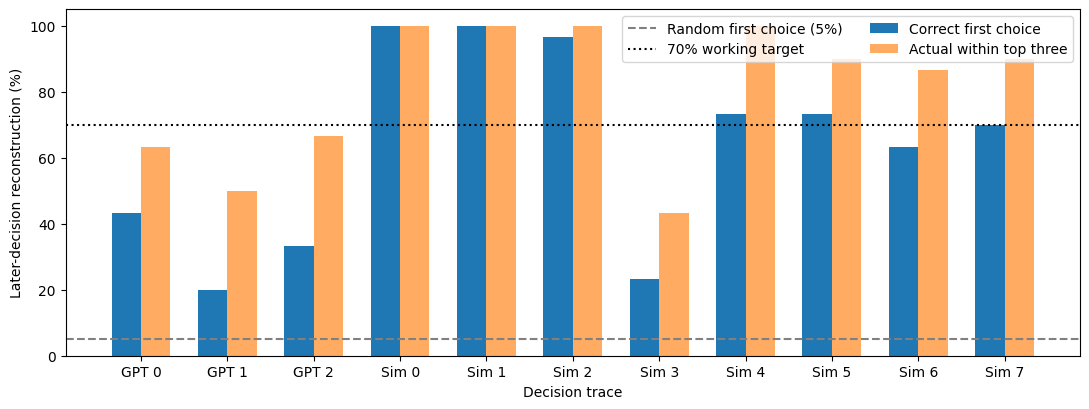

In [ ]:
# Extra publication figure: top-1 and top-3 accuracy for the later 30 decisions.
fig,ax=plt.subplots(figsize=(11,4.2))
x=np.arange(len(SUMMARY));w=.34
ax.bar(x-w/2,SUMMARY['Later top-1']*100,w,label='Correct first choice')
ax.bar(x+w/2,SUMMARY['Later top-3']*100,w,label='Actual within top three',alpha=.65)
ax.axhline(5,color='gray',ls='--',label='Random first choice (5%)')
ax.axhline(70,color='black',ls=':',label='70% working target')
ax.set_xticks(x);ax.set_xticklabels(SUMMARY['Source'])
ax.set_xlabel('Decision trace');ax.set_ylabel('Later-decision reconstruction (%)')
ax.set_ylim(0,105);ax.legend(ncol=2)
plt.tight_layout();save_figure(fig,'paper_accuracy_summary');plt.show()

*Figure — Reconstruction accuracy.* Bars summarize the **last 30 decisions only**. Top-1 is an exact match; top-3 means the agent's choice was among three model-favored candidates. The dotted 70% line is a working target rather than a formal statistical significance threshold. The cross-validation and later results are not fully independent of the earlier exploratory work.

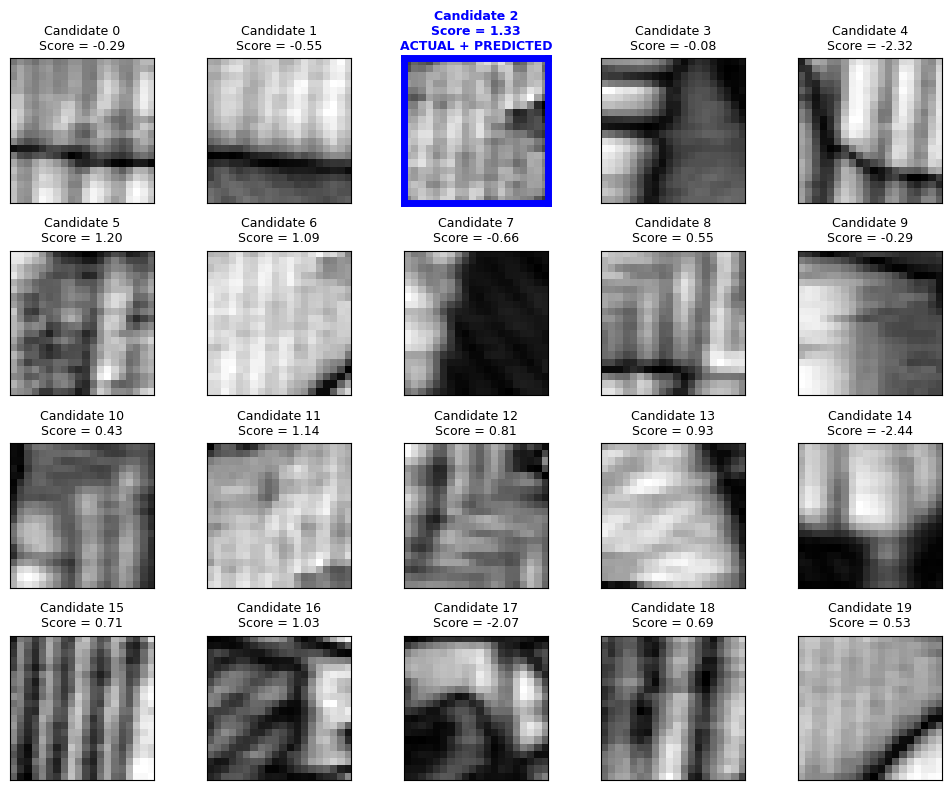

In [ ]:
# Original-style selected-vs-predicted 20-patch grid, this time for a LATER decision.
TRACE_TO_INSPECT=5
fit=TRACE_MODELS[TRACE_TO_INSPECT]
i=fit['cutoff']  # first later decision
step=STEP_IDS[TRACE_TO_INSPECT][i]
patches=traces[TRACE_TO_INSPECT][step]['patches']
actual_selected=int(CHOICES[TRACE_TO_INSPECT][i]);predicted_selected=int(fit['predicted'][i]);scores=np.asarray(fit['scores'][i])
fig,axes=plt.subplots(4,5,figsize=(10,8))
for j,ax in enumerate(axes.flat):
    ax.imshow(patches[j],cmap='gray')
    ax.set_title(f'Candidate {j}\nScore = {scores[j]:.2f}',fontsize=9)
    if j in (actual_selected,predicted_selected):
        if j==actual_selected==predicted_selected:color='blue';tag='ACTUAL + PREDICTED'
        elif j==actual_selected:color='green';tag='ACTUAL'
        else:color='red';tag='PREDICTED'
        for spine in ax.spines.values():spine.set_edgecolor(color);spine.set_linewidth(5)
        ax.set_title(f'Candidate {j}\nScore = {scores[j]:.2f}\n{tag}',fontsize=9,color=color,weight='bold')
    ax.set_xticks([]);ax.set_yticks([])
plt.tight_layout();save_figure(fig,'paper_actual_vs_predicted_patches');plt.show()

*Figure — Candidate-level example.* Every panel shows one of the 20 choices offered at a single later decision. Green identifies the actual choice, red the predicted choice, and blue indicates they coincide. These patch intensities are from the **Amplitude2** scan channel and should not be described as verified ferromagnetic domains.

## Main findings and limitations
The notebook recovers strong brightness and uniformity rules for some simulated traces and partial preferences for others. GPT traces 0–2 and some simulated traces remain difficult to reconstruct from the measured patch properties; we report that uncertainty instead of inventing a hidden rule. Since some patch images repeat across steps, the last-30-decision evaluation measures prediction on later **decisions**, not necessarily completely new physical image regions. The absence of explicit material labels means no particular magnetic or ferroelectric domain-wall mechanism has been proven.

### What we can say about the results

**Strong simulated reconstructions.** Simulated agents 0 and 1 are accurately described by selecting the brightest and darkest patch, respectively. Simulated agent 2 favors patches with low overall and local brightness variation.

**Directional and texture-related preferences.** Several other simulated traces show useful but imperfect prediction from measured image structure. The heatmaps and scoring-rule output above describe these associations; unresolved rules are labeled as such.

**GPT behavior is not fully reconstructed.** GPT 0 shows meaningful image-based predictability, but high overall reconstruction can hide a large train–later gap. The notebook separates the model's fit to recorded choices from its performance on later decisions and includes candidate-index and random-selection controls.

**Scientific scope.** This work demonstrates an approach to analyzing **recorded decisions from an Amplitude2 microscopy image**. It does not directly establish ferromagnetic domain walls, prove that GPT saw the larger scan context, or demonstrate a closed-loop autonomous experiment after changing earlier selections.

In [ ]:
strong=SUMMARY[SUMMARY['Later top-1']>=.90]
partial=SUMMARY[(SUMMARY['Later top-1']>=.70)&(SUMMARY['Later top-1']<.90)]
unsolved=SUMMARY[SUMMARY['Later top-1']<.70]
text=(
  'METHODS\nWe evaluated all 11 decision traces (100 decisions and 20 patches per decision). '
  f'For each patch we measured {len(FEATURE_NAMES)} visual characteristics including brightness, texture, boundary intensity and orientation. '
  'Separately for each trace, we compared individual features, weighted feature pairs, and fitted linear and tree models. '
  'Three-block cross-validation on the first 70 decisions selected a model; we then fit that model on the first 70 and compared its predictions with the last 30 choices.\n\n'
  'RESULTS\nStrong reconstructions (>=90% later top-1): '+', '.join(map(str,strong['Trace']))+'. '
  'Partial reconstruction (70–89%): '+', '.join(map(str,partial['Trace']))+'. '
  'Unresolved (<70%): '+', '.join(map(str,unsolved['Trace']))+'.\n\n'
  'LIMITATIONS\nCandidate patch intensity is not itself a material-property measurement, and the same physical image regions can recur. '
  'Exact patch repeats between the first 70 and last 30 decisions were quantified separately; nearby regions may still be correlated. ' +
  'Prior exploratory use of the later decisions means that these accuracy estimates are diagnostic, not independent confirmation of a uniquely identified hidden rule.'
)
print(text)
(OUTPUT_DIR/'methods_results_notes.txt').write_text(text)
SUMMARY.to_csv(OUTPUT_DIR/'trace_summary.csv',index=False)
PREDICTIONS.to_csv(OUTPUT_DIR/'decision_predictions.csv',index=False)
print('Figures and tables saved to:',OUTPUT_DIR)

METHODS
We evaluated all 11 decision traces (100 decisions and 20 patches per decision). For each patch we measured 36 visual characteristics including brightness, texture, boundary intensity and orientation. Separately for each trace, we compared individual features, weighted feature pairs, and fitted linear and tree models. Three-block cross-validation on the first 70 decisions selected a model; we then fit that model on the first 70 and compared its predictions with the last 30 choices.

RESULTS
Strong reconstructions (>=90% later top-1): 3, 4, 5. Partial reconstruction (70–89%): 7, 8, 10. Unresolved (<70%): 0, 1, 2, 6, 9.

LIMITATIONS
Candidate patch intensity is not itself a material-property measurement, and the same physical image regions can recur. Exact patch repeats between the first 70 and last 30 decisions were quantified separately; nearby regions may still be correlated. Prior exploratory use of the later decisions means that these accuracy estimates are diagnostic, not i